# Proyecto final de Analítica de Negocios
## El costo real del Fast Fashion

**Integrantes:** Juliana Valencia y María Paz Acevedo

En este trabajo escogimos el tema del Fast Fashion porque nos pareció interesante mirar qué hay detrás de la ropa que se produce y se compra constantemente.

Vamos a trabajar con una base de datos que tiene información de varias marcas. Primero la revisamos, después hacemos algunas gráficas y finalmente probamos modelos para analizar las emisiones de carbono y el sentimiento relacionado con las marcas.

## 1. Introducción

El Fast Fashion, o moda rápida, consiste en producir y vender ropa siguiendo las tendencias y sacando colecciones nuevas en poco tiempo. Es un modelo que vemos mucho hoy en día, pero también puede generar impactos por el uso de agua, las emisiones y los residuos que deja la producción.

Nos llamó la atención este tema porque es algo que usamos y consumimos con frecuencia, pero no siempre pensamos en todo lo que implica fabricar una prenda.

Para el trabajo usamos información de cinco marcas: Zara, H&M, Shein, Uniqlo y Forever 21. Con esos datos queremos revisar las emisiones de carbono y la percepción social de las marcas. La idea es aplicar lo que vimos en clase y mirar si los modelos nos ayudan a encontrar información útil.

## 2. ¿Qué queremos analizar?

Queremos revisar dos cosas: primero, si podemos estimar las emisiones de carbono usando información relacionada con la producción; y segundo, si podemos clasificar el sentimiento que aparece en los datos como positivo, neutral o negativo.

Las preguntas que nos guiaron fueron:

- ¿Qué relación tienen la producción, el consumo de agua y los residuos con las emisiones?
- ¿Hay diferencias entre las marcas y los países?
- ¿Qué tan bien podemos estimar las emisiones con los modelos?
- ¿Qué tan bien podemos clasificar el sentimiento social?

Con esto buscamos entender un poco mejor la información y pensar cómo podría servirle a una empresa.

## 3. Objetivos

**Objetivo general**

Analizar algunos datos ambientales y sociales de marcas de Fast Fashion usando herramientas de analítica de negocios.

**Objetivos específicos**

- Conocer la base de datos y sus variables.
- Revisar y organizar los datos antes de analizarlos.
- Probar modelos para estimar las emisiones de carbono.
- Clasificar el sentimiento social en las categorías disponibles.
- Revisar los resultados y plantear algunas recomendaciones.

## 4. La base de datos

La base que escogimos se llama **True Cost of Fast Fashion** y está en un archivo de Excel. Según la información que tenemos, incluye datos de cinco marcas, diez países y el período de 2015 a 2024.

Antes de empezar con los modelos vamos a revisar que el archivo tenga los registros y las columnas que necesitamos.

### 4.1 Cargar el archivo

In [1]:
# Librerías que vamos a usar
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from IPython.display import display

from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")


In [2]:
# Cargamos el archivo de Excel
uploaded = files.upload()

if not uploaded:
    raise ValueError("No se cargó ningún archivo. Vuelve a ejecutar esta celda y selecciona el Excel.")

file_name = next(iter(uploaded))
excel = pd.ExcelFile(file_name)
print("Hojas disponibles:", excel.sheet_names)

sheet = "true_cost_fast_fashion" if "true_cost_fast_fashion" in excel.sheet_names else excel.sheet_names[0]
df_original = pd.read_excel(file_name, sheet_name=sheet)
df = df_original.copy()

# Revisamos que el archivo tenga las columnas que necesita este análisis.
columnas_necesarias = [
    "Brand", "Country", "Year", "Monthly_Production_Tonnes",
    "Avg_Item_Price_USD", "Release_Cycles_Per_Year",
    "Carbon_Emissions_tCO2e", "Water_Usage_Million_Litres",
    "Landfill_Waste_Tonnes", "Avg_Worker_Wage_USD",
    "Child_Labor_Incidents", "Return_Rate_Percent",
    "Instagram_Mentions_Thousands", "TikTok_Mentions_Thousands",
    "Sentiment_Score", "Social_Sentiment_Label",
    "GDP_Contribution_Million_USD", "Env_Cost_Index",
    "Sustainability_Score", "Transparency_Index",
    "Compliance_Score", "Ethical_Rating"
]
faltantes = [col for col in columnas_necesarias if col not in df.columns]

if faltantes:
    raise ValueError(
        "Al archivo le faltan estas columnas: " + ", ".join(faltantes) +
        ". Revisa que hayas subido la base de datos correcta."
    )

print("Hoja utilizada:", sheet)
print("Tamaño de la base:", df.shape)
display(df.head())


Saving fash fashion.xlsx to fash fashion.xlsx
Hojas disponibles: ['true_cost_fast_fashion']
Hoja utilizada: true_cost_fast_fashion
Tamaño de la base: (3000, 25)


,Brand,Country,Year,Monthly_Production_Tonnes,Avg_Item_Price_USD,Release_Cycles_Per_Year,Carbon_Emissions_tCO2e,Water_Usage_Million_Litres,Landfill_Waste_Tonnes,Avg_Worker_Wage_USD,Working_Hours_Per_Week,Child_Labor_Incidents,Return_Rate_Percent,Avg_Spend_Per_Customer_USD,Shopping_Frequency_Per_Year,Instagram_Mentions_Thousands,TikTok_Mentions_Thousands,Sentiment_Score,Social_Sentiment_Label,GDP_Contribution_Million_USD,Env_Cost_Index,Sustainability_Score,Transparency_Index,Compliance_Score,Ethical_Rating
0,Shein,Indonesia,2017,574.51,19.31,16,11421.58,282.11,616.63,143.79,50,3,39.10,105.92,3,4655,3435,0.05,Neutral,608.51,0.49,29.12,61.19,13.95,1.46
1,Forever 21,Vietnam,2024,394.50,9.30,20,5571.01,289.22,795.11,167.78,44,1,11.95,101.99,4,9655,6285,-0.12,Positive,689.49,0.21,49.52,3.44,90.93,1.29
2,Uniqlo,India,2024,310.23,25.46,11,10969.00,116.39,364.33,97.81,43,2,15.88,116.53,18,8016,387,0.08,Neutral,439.78,0.63,96.53,60.70,27.60,1.48
3,Forever 21,USA,2017,218.65,13.17,13,13093.00,255.88,632.16,134.54,46,2,21.12,156.37,14,8254,1620,-0.06,Neutral,746.70,0.21,71.32,76.08,56.13,3.85
4,Zara,Indonesia,2016,1005.84,15.40,20,9548.40,142.07,830.10,144.33,56,0,25.26,113.41,15,1778,3292,-0.59,Neutral,571.42,0.95,59.89,69.48,88.05,3.12


### 4.2 ¿Qué información tiene la base?

Cada fila contiene información de una marca, un país y un año. Hay variables que nos sirven para separar o comparar grupos, como la marca y el país, y otras que son numéricas, como producción, consumo de agua y emisiones.

En la siguiente tabla organizamos algunas de las variables que vamos a utilizar.

In [3]:
print("Registros:", df.shape[0])
print("Variables:", df.shape[1])
print("Años:", sorted(df["Year"].dropna().unique().tolist()) if "Year" in df else "No disponible")
print("Marcas:", sorted(df["Brand"].dropna().unique().tolist()) if "Brand" in df else "No disponible")
print("Países:", df["Country"].nunique() if "Country" in df else "No disponible")
display(df.dtypes.rename("Tipo de dato").to_frame())


Registros: 3000
Variables: 25
Años: [2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024]
Marcas: ['Forever 21', 'H&M', 'Shein', 'Uniqlo', 'Zara']
Países: 10


,Tipo de dato
Brand,object
Country,object
Year,int64
Monthly_Production_Tonnes,float64
Avg_Item_Price_USD,float64
Release_Cycles_Per_Year,int64
Carbon_Emissions_tCO2e,float64
Water_Usage_Million_Litres,float64
Landfill_Waste_Tonnes,float64
Avg_Worker_Wage_USD,float64


In [4]:
# Variables de la base
variable_dictionary = pd.DataFrame([
    ("Brand", "Marca", "Categórica", "Agrupamiento"),
    ("Country", "País de operación", "Categórica", "Agrupamiento"),
    ("Year", "Año del registro (2015–2024)", "Numérica discreta", "Temporal"),
    ("Monthly_Production_Tonnes", "Producción mensual en toneladas", "Numérica", "Explicativa"),
    ("Avg_Item_Price_USD", "Precio promedio por prenda (USD)", "Numérica", "Explicativa"),
    ("Release_Cycles_Per_Year", "Colecciones o lanzamientos al año", "Numérica discreta", "Explicativa"),
    ("Carbon_Emissions_tCO2e", "Emisiones en toneladas de CO2 equivalente", "Numérica", "Objetivo de pronóstico"),
    ("Water_Usage_Million_Litres", "Agua utilizada (millones de litros)", "Numérica", "Explicativa"),
    ("Landfill_Waste_Tonnes", "Residuos textiles enviados a relleno (toneladas)", "Numérica", "Explicativa"),
    ("Avg_Worker_Wage_USD", "Salario promedio del trabajador (USD)", "Numérica", "Explicativa"),
    ("Working_Hours_Per_Week", "Horas trabajadas por semana", "Numérica discreta", "Explicativa"),
    ("Child_Labor_Incidents", "Casos reportados de trabajo infantil", "Numérica discreta", "Explicativa"),
    ("Return_Rate_Percent", "Porcentaje de prendas devueltas", "Numérica", "Explicativa"),
    ("Avg_Spend_Per_Customer_USD", "Gasto promedio por cliente (USD)", "Numérica", "Explicativa"),
    ("Shopping_Frequency_Per_Year", "Compras por cliente al año", "Numérica discreta", "Explicativa"),
    ("Instagram_Mentions_Thousands", "Menciones en Instagram (miles)", "Numérica", "Explicativa"),
    ("TikTok_Mentions_Thousands", "Menciones en TikTok (miles)", "Numérica", "Explicativa"),
    ("Sentiment_Score", "Puntaje de sentimiento entre -1 y 1", "Numérica", "Explicativa candidata; revisar posible fuga"),
    ("Social_Sentiment_Label", "Sentimiento positivo, neutral o negativo", "Categórica", "Objetivo de clasificación"),
    ("GDP_Contribution_Million_USD", "Aporte al PIB (millones USD)", "Numérica", "Explicativa"),
    ("Env_Cost_Index", "Índice de costo ambiental", "Numérica", "Explicativa"),
    ("Sustainability_Score", "Puntaje de sostenibilidad (0 a 100)", "Numérica", "Explicativa"),
    ("Transparency_Index", "Índice de transparencia (0 a 100)", "Numérica", "Explicativa"),
    ("Compliance_Score", "Puntaje de cumplimiento (0 a 100)", "Numérica", "Explicativa"),
    ("Ethical_Rating", "Calificación ética (0 a 5)", "Numérica", "Explicativa"),
], columns=["Variable", "Descripción", "Tipo", "Rol"])
display(variable_dictionary)


,Variable,Descripción,Tipo,Rol
0,Brand,Marca,Categórica,Agrupamiento
1,Country,País de operación,Categórica,Agrupamiento
2,Year,Año del registro (2015–2024),Numérica discreta,Temporal
3,Monthly_Production_Tonnes,Producción mensual en toneladas,Numérica,Explicativa
4,Avg_Item_Price_USD,Precio promedio por prenda (USD),Numérica,Explicativa
5,Release_Cycles_Per_Year,Colecciones o lanzamientos al año,Numérica discreta,Explicativa
6,Carbon_Emissions_tCO2e,Emisiones en toneladas de CO2 equivalente,Numérica,Objetivo de pronóstico
7,Water_Usage_Million_Litres,Agua utilizada (millones de litros),Numérica,Explicativa
8,Landfill_Waste_Tonnes,Residuos textiles enviados a relleno (toneladas),Numérica,Explicativa
9,Avg_Worker_Wage_USD,Salario promedio del trabajador (USD),Numérica,Explicativa


### 4.3 Revisamos los datos

Antes de hacer las gráficas revisamos si había datos vacíos, filas repetidas o valores que llamaran la atención.

También miramos algunos valores negativos que aparecían en variables como consumo de agua, salario y aporte al PIB. Para este ejercicio los reemplazamos por la mediana de los valores válidos de cada columna. Conservamos la base original para poder comparar los cambios.

In [5]:
print("Total de valores nulos:", int(df.isna().sum().sum()))
display(df.isna().sum().to_frame("Valores nulos"))
print("Filas duplicadas:", int(df.duplicated().sum()))

negative_cols = [
    "GDP_Contribution_Million_USD",
    "Water_Usage_Million_Litres",
    "Avg_Worker_Wage_USD"
]
negative_counts = {col: int((df[col] < 0).sum()) for col in negative_cols}
print("Valores negativos antes de limpiar:", negative_counts)
print("Total de negativos en las tres variables:", sum(negative_counts.values()))


Total de valores nulos: 0


,Valores nulos
Brand,0
Country,0
Year,0
Monthly_Production_Tonnes,0
Avg_Item_Price_USD,0
Release_Cycles_Per_Year,0
Carbon_Emissions_tCO2e,0
Water_Usage_Million_Litres,0
Landfill_Waste_Tonnes,0
Avg_Worker_Wage_USD,0


Filas duplicadas: 0
Valores negativos antes de limpiar: {'GDP_Contribution_Million_USD': 13, 'Water_Usage_Million_Litres': 2, 'Avg_Worker_Wage_USD': 2}
Total de negativos en las tres variables: 17


In [6]:
# Corregimos los valores negativos para poder seguir con el análisis
df_clean = df.copy()
cleaning_log = []

for col in negative_cols:
    mask = df_clean[col] < 0
    count = int(mask.sum())
    median_nonnegative = df_clean.loc[df_clean[col] >= 0, col].median()
    df_clean.loc[mask, col] = median_nonnegative
    cleaning_log.append({
        "Variable": col,
        "Negativos reemplazados": count,
        "Mediana usada": median_nonnegative
    })

display(pd.DataFrame(cleaning_log))
print("Negativos restantes:")
display((df_clean[negative_cols] < 0).sum().to_frame("Cantidad"))


,Variable,Negativos reemplazados,Mediana usada
0,GDP_Contribution_Million_USD,13,505.020
1,Water_Usage_Million_Litres,2,200.335
2,Avg_Worker_Wage_USD,2,149.705


Negativos restantes:


,Cantidad
GDP_Contribution_Million_USD,0
Water_Usage_Million_Litres,0
Avg_Worker_Wage_USD,0


### 4.4 Valores que se salen de lo normal

También revisamos si había valores muy alejados de los demás usando el método IQR. No los quitamos automáticamente, porque podrían ser datos reales. Los dejamos identificados para tener cuidado al momento de interpretar los resultados.

In [7]:
numeric_cols_all = df_clean.select_dtypes(include=np.number).columns.tolist()
outlier_rows = []

for col in numeric_cols_all:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((df_clean[col] < low) | (df_clean[col] > high)).sum())
    outlier_rows.append((col, low, high, n_out))

outlier_table = pd.DataFrame(outlier_rows, columns=["Variable", "Límite inferior IQR", "Límite superior IQR", "Posibles atípicos"])
display(outlier_table.sort_values("Posibles atípicos", ascending=False))


,Variable,Límite inferior IQR,Límite superior IQR,Posibles atípicos
11,Avg_Spend_Per_Customer_USD,40.86875,199.57875,23
1,Monthly_Production_Tonnes,95.70000,897.46000,22
5,Water_Usage_Million_Litres,39.95000,361.09000,18
4,Carbon_Emissions_tCO2e,1711.34375,18193.39375,16
6,Landfill_Waste_Tonnes,238.37875,1351.60875,14
2,Avg_Item_Price_USD,6.37000,33.49000,14
7,Avg_Worker_Wage_USD,16.46000,284.12000,14
16,GDP_Contribution_Million_USD,-21.14375,1027.32625,13
3,Release_Cycles_Per_Year,-6.00000,42.00000,0
0,Year,2009.50000,2029.50000,0


## 5. Miramos los datos antes de aplicar los modelos

En esta parte hacemos algunas gráficas y tablas para entender mejor la base. Comparamos las emisiones por año, marca y país; también revisamos cómo están distribuidas las categorías de sentimiento y qué relación tienen algunas variables numéricas.

Esto nos da una primera idea de los datos con los que vamos a trabajar.

In [8]:
display(df_clean.describe(include="all").T)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Brand,3000,5,H&M,650,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country,3000,10,India,314,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Year,3000.0,NaN,NaN,NaN,2019.529667,2.894002,2015.0,2017.0,2020.0,2022.0,2024.0
Monthly_Production_Tonnes,3000.0,NaN,NaN,NaN,497.31989,149.543176,3.82,396.36,495.535,596.8,1005.84
Avg_Item_Price_USD,3000.0,NaN,NaN,NaN,19.936187,4.919126,1.09,16.54,19.89,23.32,36.46
Release_Cycles_Per_Year,3000.0,NaN,NaN,NaN,17.757333,6.981358,6.0,12.0,18.0,24.0,29.0
Carbon_Emissions_tCO2e,3000.0,NaN,NaN,NaN,10003.873717,3017.980553,206.09,7892.1125,9926.94,12012.625,19585.47
Water_Usage_Million_Litres,3000.0,NaN,NaN,NaN,201.076387,60.193957,4.88,160.3775,200.335,240.6625,403.83
Landfill_Waste_Tonnes,3000.0,NaN,NaN,NaN,795.028837,201.440989,58.24,655.84,799.995,934.1475,1480.38
Avg_Worker_Wage_USD,3000.0,NaN,NaN,NaN,149.94155,49.558557,3.62,116.8325,149.705,183.7475,326.45


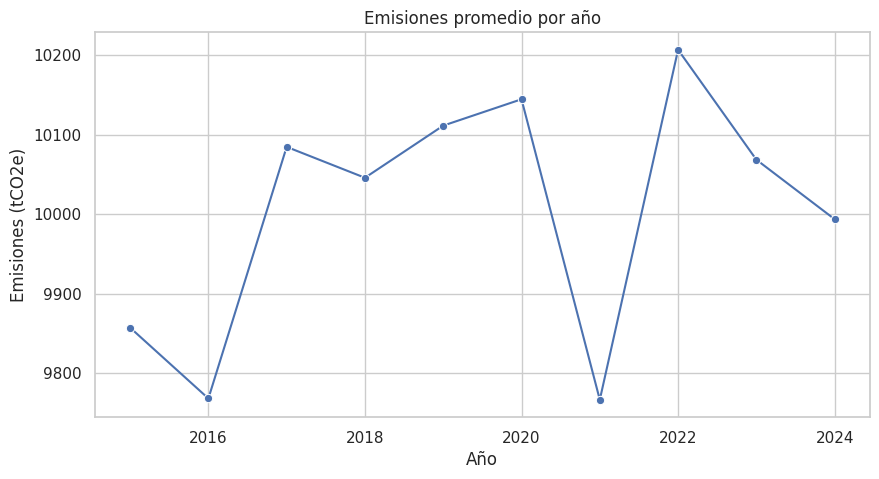

,Year,Carbon_Emissions_tCO2e
0,2015,9857.441798
1,2016,9768.329544
2,2017,10084.860139
3,2018,10045.996181
4,2019,10111.592527
5,2020,10144.782792
6,2021,9766.725723
7,2022,10207.058275
8,2023,10068.749840
9,2024,9993.832957


In [9]:
# Emisiones promedio por año
annual = df_clean.groupby("Year", as_index=False)["Carbon_Emissions_tCO2e"].mean()
plt.figure(figsize=(10, 5))
sns.lineplot(data=annual, x="Year", y="Carbon_Emissions_tCO2e", marker="o")
plt.title("Emisiones promedio por año")
plt.xlabel("Año")
plt.ylabel("Emisiones (tCO2e)")
plt.show()
display(annual)


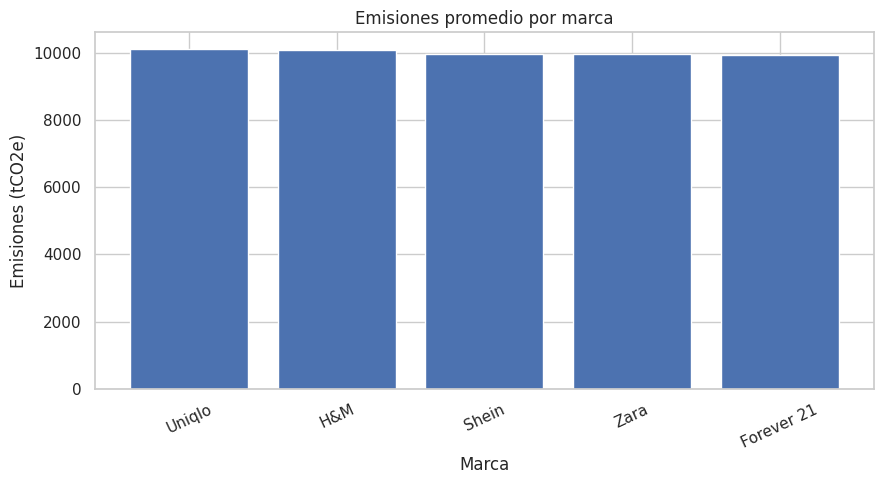

,Brand,Carbon_Emissions_tCO2e
3,Uniqlo,10097.616420
1,H&M,10084.840031
2,Shein,9951.848242
4,Zara,9945.682261
0,Forever 21,9933.496596


In [10]:
# Emisiones promedio por marca
brand_emissions = (
    df_clean.groupby("Brand", as_index=False)["Carbon_Emissions_tCO2e"]
    .mean()
    .sort_values("Carbon_Emissions_tCO2e", ascending=False)
)

plt.figure(figsize=(9, 5))
plt.bar(brand_emissions["Brand"], brand_emissions["Carbon_Emissions_tCO2e"])
plt.title("Emisiones promedio por marca")
plt.xlabel("Marca")
plt.ylabel("Emisiones (tCO2e)")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()
display(brand_emissions)


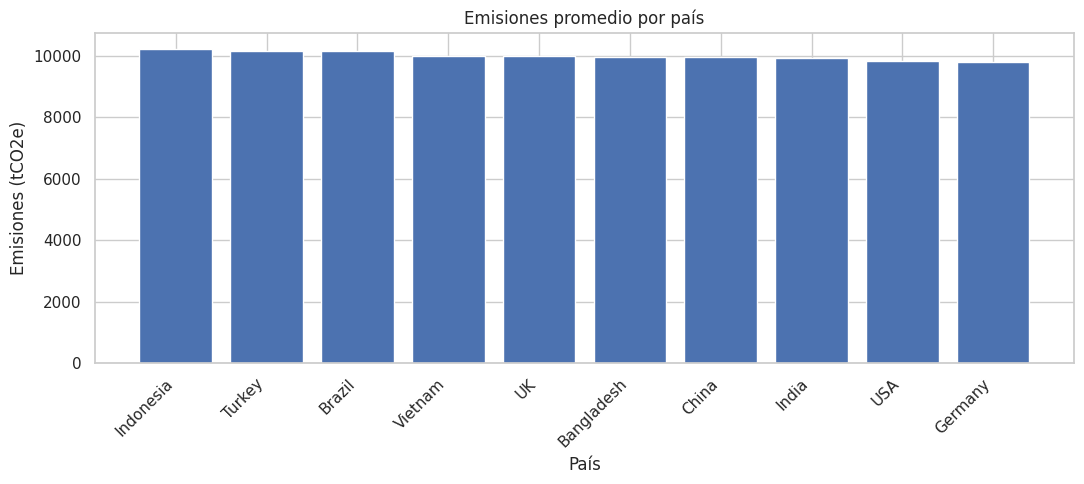

,Country,Carbon_Emissions_tCO2e
5,Indonesia,10242.742600
6,Turkey,10169.509400
1,Brazil,10150.814676
9,Vietnam,10002.609192
7,UK,9987.093495
0,Bangladesh,9980.411250
2,China,9960.597370
4,India,9934.920955
8,USA,9824.683910
3,Germany,9801.101780


In [11]:
# Emisiones promedio por país
country_emissions = (
    df_clean.groupby("Country", as_index=False)["Carbon_Emissions_tCO2e"]
    .mean()
    .sort_values("Carbon_Emissions_tCO2e", ascending=False)
)

plt.figure(figsize=(11, 5))
plt.bar(country_emissions["Country"], country_emissions["Carbon_Emissions_tCO2e"])
plt.title("Emisiones promedio por país")
plt.xlabel("País")
plt.ylabel("Emisiones (tCO2e)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
display(country_emissions)


,Registros
Social_Sentiment_Label,
Neutral,1027
Positive,998
Negative,975


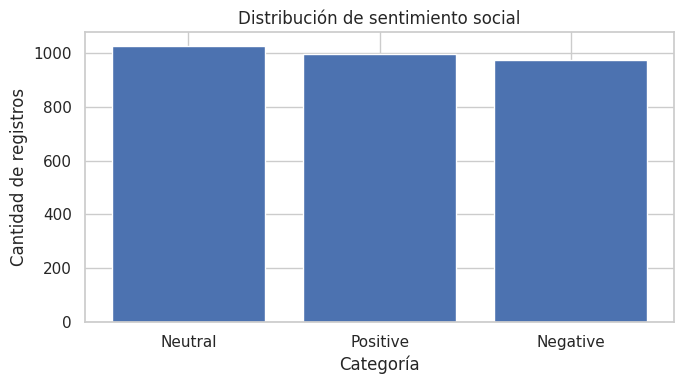

In [12]:
# Cantidad de registros por sentimiento
sentiment_counts = df_clean["Social_Sentiment_Label"].value_counts()
display(sentiment_counts.to_frame("Registros"))

plt.figure(figsize=(7, 4))
plt.bar(sentiment_counts.index, sentiment_counts.values)
plt.title("Distribución de sentimiento social")
plt.xlabel("Categoría")
plt.ylabel("Cantidad de registros")
plt.tight_layout()
plt.show()


,Correlación de Pearson con emisiones
Avg_Worker_Wage_USD,0.050532
Compliance_Score,0.032846
Child_Labor_Incidents,-0.028476
Monthly_Production_Tonnes,-0.025524
Avg_Spend_Per_Customer_USD,-0.021019
Landfill_Waste_Tonnes,0.020693
Env_Cost_Index,-0.019529
Year,0.018188
TikTok_Mentions_Thousands,0.016846
Water_Usage_Million_Litres,-0.012094


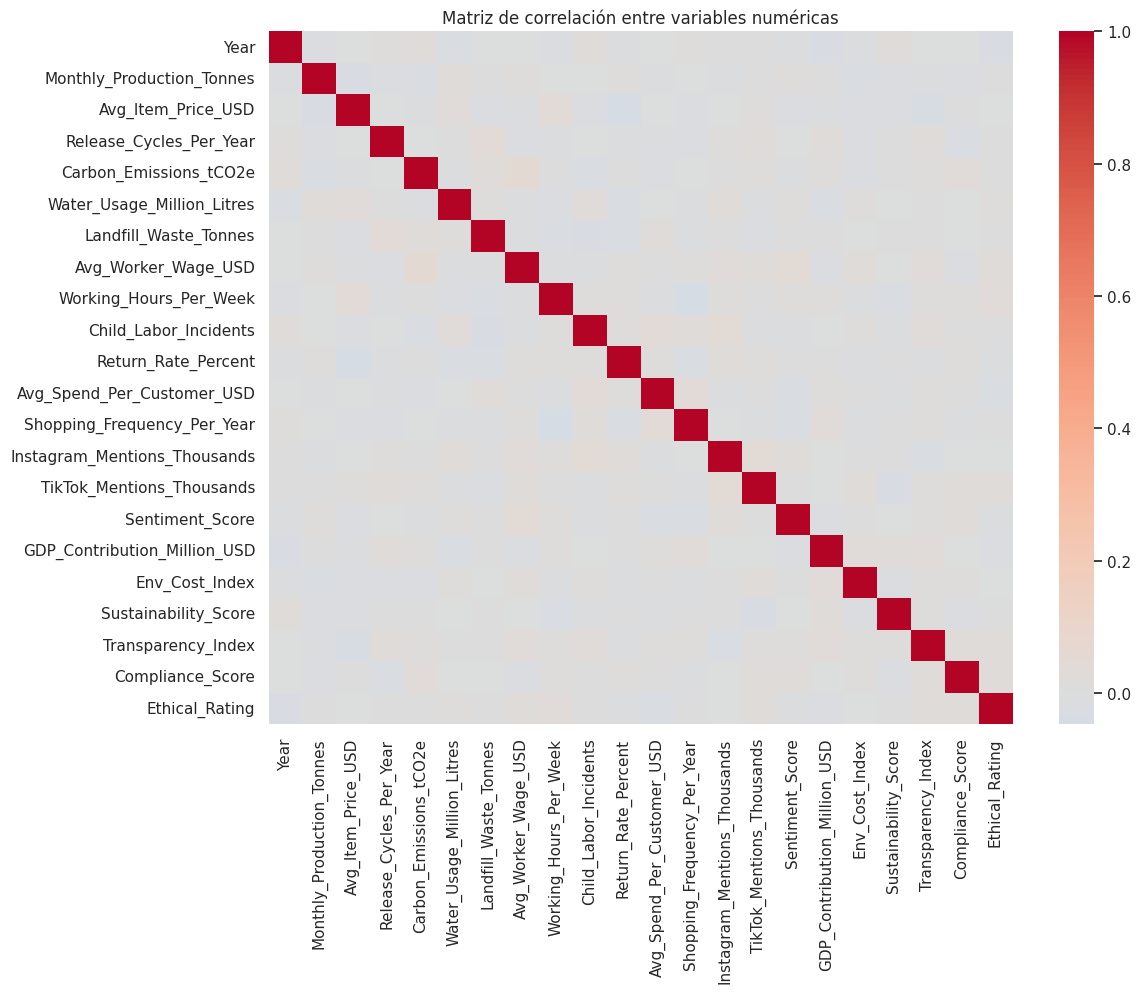

In [13]:
# Revisamos qué variables tienen mayor correlación con las emisiones
corr = df_clean.select_dtypes(include=np.number).corr()
emission_corr = corr["Carbon_Emissions_tCO2e"].drop("Carbon_Emissions_tCO2e").sort_values(key=np.abs, ascending=False)
display(emission_corr.to_frame("Correlación de Pearson con emisiones"))

plt.figure(figsize=(12, 9))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Matriz de correlación entre variables numéricas")
plt.show()


## 6. Modelos que vamos a probar

Para el proyecto escogimos un análisis de pronóstico y otro de clasificación.

### 6.1 Estimar las emisiones

La variable que queremos estimar es `Carbon_Emissions_tCO2e`.

Vamos a comparar dos modelos:
- **Regresión Lineal Múltiple:** busca estimar las emisiones a partir de varias variables.
- **Random Forest:** combina varios árboles para hacer una predicción.

Usamos datos de producción, ciclos de lanzamiento, consumo de agua, residuos, precio, marca, país y año.

Para revisar qué tan bien funcionan usamos R², RMSE y MAE. También separamos los datos en una parte para entrenar y otra para probar los modelos.

### 6.2 Clasificar el sentimiento

En esta parte queremos clasificar `Social_Sentiment_Label` en positivo, neutral o negativo.

Para hacerlo usamos un **Árbol de Decisión** y variables como las menciones en redes, sostenibilidad, transparencia, cumplimiento y marca.

Revisamos el resultado con Accuracy, F1 y la matriz de confusión.

Dejamos por fuera `Sentiment_Score` del modelo principal porque puede estar muy relacionado con la categoría que queremos predecir. Así evitamos que el modelo tenga una ventaja que no sería tan real.

## 7. Pronóstico de emisiones

En esta sección preparamos los datos y entrenamos los dos modelos que escogimos. Después comparamos sus resultados para ver cuál tuvo un menor error al estimar las emisiones.

In [14]:
# Datos para el pronóstico
reg_features = [
    "Monthly_Production_Tonnes",
    "Release_Cycles_Per_Year",
    "Water_Usage_Million_Litres",
    "Landfill_Waste_Tonnes",
    "Avg_Item_Price_USD",
    "Env_Cost_Index",
    "Brand",
    "Country",
    "Year"
]
reg_target = "Carbon_Emissions_tCO2e"

X_reg = df_clean[reg_features]
y_reg = df_clean[reg_target]

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.20, random_state=42
)

reg_cat = ["Brand", "Country"]
reg_num = [c for c in reg_features if c not in reg_cat]

preprocess_reg = ColumnTransformer([
    ("numeric", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), reg_num),
    ("categorical", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))]), reg_cat)
])

linear_reg = Pipeline([
    ("preprocess", preprocess_reg),
    ("model", LinearRegression())
])

random_forest = Pipeline([
    ("preprocess", preprocess_reg),
    ("model", RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1))
])

linear_reg.fit(X_train_reg, y_train_reg)
random_forest.fit(X_train_reg, y_train_reg)

pred_linear = linear_reg.predict(X_test_reg)
pred_rf = random_forest.predict(X_test_reg)


In [15]:
def regression_metrics(y_true, y_pred):
    return {
        "R²": r2_score(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE": mean_absolute_error(y_true, y_pred)
    }

reg_results = pd.DataFrame({
    "Regresión Lineal Múltiple": regression_metrics(y_test_reg, pred_linear),
    "Random Forest Regressor": regression_metrics(y_test_reg, pred_rf)
}).T
display(reg_results)


,R²,RMSE,MAE
Regresión Lineal Múltiple,-0.024388,3039.357579,2452.097558
Random Forest Regressor,-0.029972,3047.629721,2457.540872


In [16]:
# Comparamos con una predicción sencilla: usar el promedio
baseline_reg = DummyRegressor(strategy="mean")
baseline_reg.fit(X_train_reg, y_train_reg)
pred_baseline_reg = baseline_reg.predict(X_test_reg)
display(pd.DataFrame([regression_metrics(y_test_reg, pred_baseline_reg)], index=["Línea base: promedio"]))


,R²,RMSE,MAE
Línea base: promedio,-0.000152,3003.187632,2398.06714


In [17]:
# Comparamos los modelos con validación cruzada
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_rows = []
for model_name, model in [("Regresión Lineal", linear_reg), ("Random Forest", random_forest)]:
    scores = cross_validate(
        model, X_train_reg, y_train_reg, cv=kf,
        scoring={"r2": "r2", "mae": "neg_mean_absolute_error", "mse": "neg_mean_squared_error"},
        n_jobs=-1
    )
    cv_rows.append({
        "Modelo": model_name,
        "R² promedio CV": scores["test_r2"].mean(),
        "MAE promedio CV": -scores["test_mae"].mean(),
        "RMSE promedio CV": np.sqrt(-scores["test_mse"]).mean()
    })
display(pd.DataFrame(cv_rows))


,Modelo,R² promedio CV,MAE promedio CV,RMSE promedio CV
0,Regresión Lineal,-0.013604,2426.558714,3035.953779
1,Random Forest,-0.056202,2475.338457,3099.852968


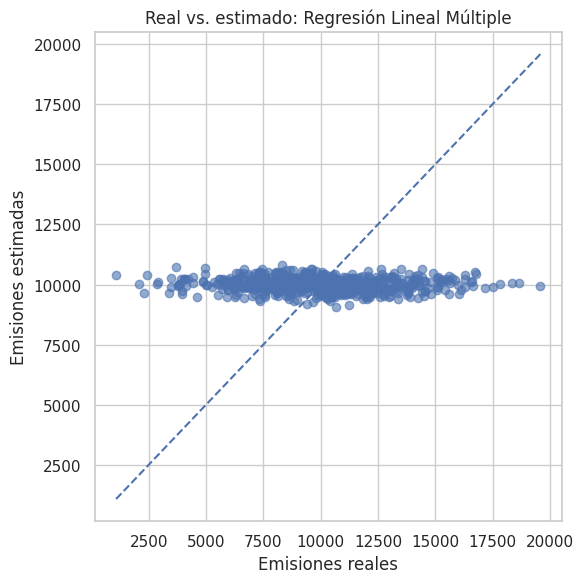

Modelo con menor RMSE en prueba: Regresión Lineal Múltiple


In [18]:
# Comparamos los valores reales con los que predijo el modelo
best_reg_name = reg_results["RMSE"].idxmin()
best_reg_pred = pred_linear if best_reg_name == "Regresión Lineal Múltiple" else pred_rf

plt.figure(figsize=(6, 6))
plt.scatter(y_test_reg, best_reg_pred, alpha=0.6)
lims = [
    min(y_test_reg.min(), best_reg_pred.min()),
    max(y_test_reg.max(), best_reg_pred.max())
]
plt.plot(lims, lims, "--")
plt.xlabel("Emisiones reales")
plt.ylabel("Emisiones estimadas")
plt.title(f"Real vs. estimado: {best_reg_name}")
plt.tight_layout()
plt.show()
print("Modelo con menor RMSE en prueba:", best_reg_name)


## 8. Clasificación del sentimiento

Ahora trabajamos con el Árbol de Decisión. La idea es que el modelo aprenda a clasificar los registros según el sentimiento indicado en la base y después revisamos qué tan bien lo hace con los datos de prueba.

In [19]:
# Dejamos por fuera Sentiment_Score para evitar usar una variable demasiado parecida a la respuesta
class_features = [
    "Instagram_Mentions_Thousands",
    "TikTok_Mentions_Thousands",
    "Sustainability_Score",
    "Transparency_Index",
    "Compliance_Score",
    "Ethical_Rating",
    "Child_Labor_Incidents",
    "Avg_Item_Price_USD",
    "Return_Rate_Percent",
    "Brand"
]
class_target = "Social_Sentiment_Label"

X_class = df_clean[class_features]
y_class = df_clean[class_target]

X_train_class, X_test_class, y_train_class, y_test_class = train_test_split(
    X_class, y_class, test_size=0.20, random_state=42, stratify=y_class
)

class_cat = ["Brand"]
class_num = [c for c in class_features if c not in class_cat]

preprocess_class = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median"), class_num),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), class_cat)
])

decision_tree = Pipeline([
    ("preprocess", preprocess_class),
    ("model", DecisionTreeClassifier(max_depth=5, min_samples_leaf=10, random_state=42))
])

decision_tree.fit(X_train_class, y_train_class)
pred_class = decision_tree.predict(X_test_class)

print("Accuracy:", round(accuracy_score(y_test_class, pred_class), 4))
print("F1 macro:", round(f1_score(y_test_class, pred_class, average="macro"), 4))
print("\nReporte por clase:")
print(classification_report(y_test_class, pred_class, zero_division=0))


Accuracy: 0.33
F1 macro: 0.3004

Reporte por clase:
              precision    recall  f1-score   support

    Negative       0.32      0.46      0.37       195
     Neutral       0.31      0.08      0.13       205
    Positive       0.35      0.46      0.40       200

    accuracy                           0.33       600
   macro avg       0.32      0.33      0.30       600
weighted avg       0.32      0.33      0.30       600



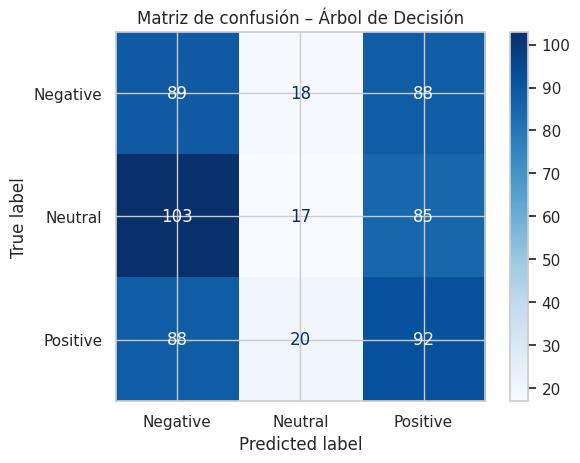

In [20]:
# Matriz de confusión
labels = decision_tree.classes_
cm = confusion_matrix(y_test_class, pred_class, labels=labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(cmap="Blues", values_format="d")
plt.title("Matriz de confusión – Árbol de Decisión")
plt.show()


In [21]:
# Línea base de clasificación: siempre predecir la clase más frecuente en entrenamiento
baseline_class = DummyClassifier(strategy="most_frequent")
baseline_class.fit(X_train_class, y_train_class)
pred_baseline_class = baseline_class.predict(X_test_class)
print("Accuracy línea base:", round(accuracy_score(y_test_class, pred_baseline_class), 4))
print("F1 macro línea base:", round(f1_score(y_test_class, pred_baseline_class, average="macro"), 4))


Accuracy línea base: 0.3417
F1 macro línea base: 0.1698


In [22]:
# Validación cruzada estratificada de 5 particiones, solo sobre entrenamiento
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_class = cross_validate(
    decision_tree, X_train_class, y_train_class, cv=skf,
    scoring={"accuracy": "accuracy", "f1_macro": "f1_macro"}
)
print("Accuracy promedio CV:", round(cv_class["test_accuracy"].mean(), 4))
print("F1 macro promedio CV:", round(cv_class["test_f1_macro"].mean(), 4))


Accuracy promedio CV: 0.3388
F1 macro promedio CV: 0.3271


,Variable,Importancia
0,numeric__Instagram_Mentions_Thousands,0.227841
5,numeric__Ethical_Rating,0.227446
1,numeric__TikTok_Mentions_Thousands,0.215393
4,numeric__Compliance_Score,0.110156
2,numeric__Sustainability_Score,0.095502
6,numeric__Child_Labor_Incidents,0.053126
8,numeric__Return_Rate_Percent,0.037309
13,categorical__Brand_Zara,0.033227
3,numeric__Transparency_Index,0.000000
7,numeric__Avg_Item_Price_USD,0.000000


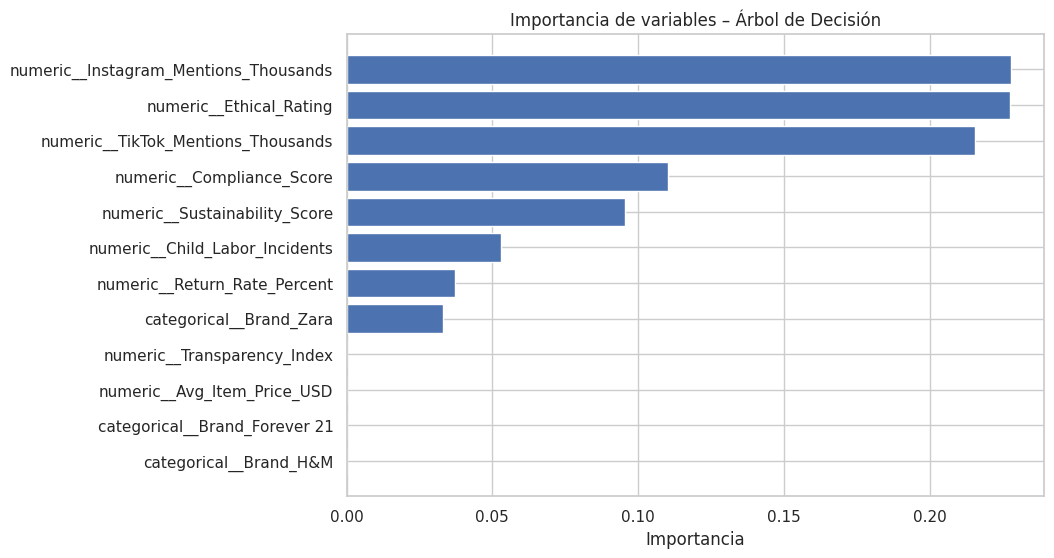

In [23]:
# Importancia de variables del árbol
feature_names = decision_tree.named_steps["preprocess"].get_feature_names_out()
importances = decision_tree.named_steps["model"].feature_importances_
importance_df = pd.DataFrame({"Variable": feature_names, "Importancia": importances}).sort_values("Importancia", ascending=False)
display(importance_df.head(15))

top_imp = importance_df.head(12).sort_values("Importancia")
plt.figure(figsize=(9, 6))
plt.barh(top_imp["Variable"], top_imp["Importancia"])
plt.title("Importancia de variables – Árbol de Decisión")
plt.xlabel("Importancia")
plt.show()


### 8.1 Una revisión sobre el puntaje de sentimiento

Revisamos cómo se comporta `Sentiment_Score` frente a la categoría de sentimiento. No la usamos para entrenar el modelo principal porque podría estar dando información muy parecida a la respuesta que queremos obtener.

In [24]:
display(pd.crosstab(df_clean["Social_Sentiment_Label"], pd.cut(
    df_clean["Sentiment_Score"], bins=[-1.01, -0.33, 0.33, 1.01],
    labels=["Puntaje bajo", "Puntaje medio", "Puntaje alto"]
), normalize="index").round(3))

print("Correlación entre puntaje y etiqueta codificada no se calcula como si la etiqueta fuera numérica: la etiqueta es categórica.")


Sentiment_Score,Puntaje bajo,Puntaje medio,Puntaje alto
Social_Sentiment_Label,,,
Negative,0.328,0.349,0.323
Neutral,0.346,0.312,0.343
Positive,0.338,0.335,0.328


Correlación entre puntaje y etiqueta codificada no se calcula como si la etiqueta fuera numérica: la etiqueta es categórica.


## 9. ¿Qué nos dicen los resultados?

Esta parte la completamos después de ejecutar el notebook. La idea es escribir lo que realmente muestran las tablas y las gráficas, sin inventar resultados.

Podemos guiarnos por estas preguntas:

- ¿Cuántos registros y variables tiene finalmente la base?
- ¿Qué encontramos al revisar los datos vacíos, duplicados y negativos?
- ¿Qué marca, país o año aparece con mayores emisiones promedio?
- ¿Qué variables muestran mayor relación con las emisiones?
- ¿Cuál de los modelos de pronóstico tuvo menor error?
- ¿El modelo de clasificación logró reconocer las tres categorías de sentimiento?
- ¿Qué errores se ven en la matriz de confusión?

Al comparar los modelos debemos explicar qué significan sus métricas. Un RMSE o MAE más bajo indica un error menor. El R² ayuda a ver qué tanto se ajustan las predicciones. En clasificación, Accuracy muestra la proporción de aciertos y F1 ayuda a revisar el desempeño teniendo en cuenta precisión y recuperación.

También hay que tener presente que una relación entre dos variables no significa necesariamente que una cause la otra. Los resultados dependen de la información que trae esta base.

## 10. Cosas que debemos tener en cuenta

El análisis tiene algunas limitaciones. Solo estamos trabajando con las marcas, países y años que aparecen en el archivo, así que no podemos decir que los resultados representen a toda la industria.

Tampoco tenemos cómo comprobar desde este ejercicio el origen de cada dato. Además, pueden existir otros factores que influyan en las emisiones y que no estén incluidos en la base.

Por eso los modelos sirven como apoyo para revisar información, pero sus resultados no deben tomarse como verdades absolutas.

## 11. Uso responsable de los resultados

Es importante no sacar conclusiones exageradas. Por ejemplo, que una marca tenga un promedio más alto en una gráfica no significa por sí solo que sea la más contaminante en todos sus procesos.

También debemos recordar que las categorías de sentimiento no representan la opinión de todos los consumidores. Los resultados se deben revisar junto con otra información antes de tomar decisiones.

## 12. Conclusiones

Con este trabajo pudimos conocer un poco más sobre el impacto que tiene la industria del Fast Fashion en el medio ambiente. A través de los datos analizamos diferentes aspectos relacionados con las emisiones de carbono, el consumo de agua, los residuos y la producción de las marcas.

También aprendimos a organizar y preparar una base de datos, realizar gráficas y utilizar modelos de analítica para estudiar la información. Durante el desarrollo del proyecto entendimos que estas herramientas permiten encontrar patrones y analizar situaciones que pueden ser importantes para las empresas.

Por otro lado, nos dimos cuenta de que trabajar con datos requiere revisar bien la información y tener en cuenta que los resultados de los modelos no siempre son perfectos. Por eso, es importante interpretar las métricas y reconocer las limitaciones del análisis.

En general, este proyecto nos permitió poner en práctica los temas vistos en clase y entender cómo la analítica de negocios puede ayudar a estudiar problemas reales, como el impacto ambiental de la industria de la moda.

## 13. Algunas recomendaciones

Según los resultados que obtengamos, podemos considerar estas recomendaciones:

- Hacer seguimiento a las emisiones y al consumo de agua.
- Revisar qué procesos pueden estar generando más residuos.
- Comparar los indicadores entre períodos y marcas, teniendo en cuenta sus diferencias.
- Seguir revisando la percepción de los consumidores.
- Mantener los datos organizados y corregir los errores solo cuando haya una razón clara.

Estas recomendaciones se deben ajustar a lo que realmente encontremos en el análisis.

## 14. Fuentes

- Kaggle. *True Cost of Fast Fashion*. Base de datos utilizada en el proyecto. **https://www.kaggle.com/datasets/khushikyad001/the-true-cost-of-fast-fashion-impact.**
- Documentación de pandas: https://pandas.pydata.org/docs/
- Documentación de scikit-learn: https://scikit-learn.org/stable/
- Documentación de Matplotlib: https://matplotlib.org/stable/
- Documentación de Seaborn: https://seaborn.pydata.org/